In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

excel_file = pd.ExcelFile(file_name)

print("Available sheets:", excel_file.sheet_names)

users = pd.read_excel(file_name, sheet_name="Users")
courses = pd.read_excel(file_name, sheet_name="Courses")
transactions = pd.read_excel(file_name, sheet_name="Transactions")
teachers = pd.read_excel(file_name, sheet_name="Teachers")

print("Dataset loaded successfully!")


Saving EduPro Online Platform.xlsx to EduPro Online Platform (1).xlsx
Available sheets: ['Users', 'Teachers', 'Courses', 'Transactions']
Dataset loaded successfully!


In [ ]:

datasets = {
    "Users": users,
    "Courses": courses,
    "Transactions": transactions,
    "Teachers": teachers
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)
    print("\nFirst 5 rows:")
    display(df.head())



--- Users ---
Rows and columns: (3000, 5)

Column names:
['UserID', 'UserName', 'Age', 'Gender', 'Email']

Data types:
UserID      object
UserName    object
Age          int64
Gender      object
Email       object
dtype: object

First 5 rows:


,UserID,UserName,Age,Gender,Email
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com
1,U00002,angela22,29,Female,hallrandy@hotmail.com
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com
3,U00004,fthornton,23,Female,christensencatherine@outlook.com
4,U00005,fostergeoffrey,21,Male,karenfuentes@yahoo.com



--- Courses ---
Rows and columns: (60, 8)

Column names:
['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

Data types:
CourseID           object
CourseName         object
CourseCategory     object
CourseType         object
CourseLevel        object
CoursePrice       float64
CourseDuration    float64
CourseRating      float64
dtype: object

First 5 rows:


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28



--- Transactions ---
Rows and columns: (10000, 7)

Column names:
['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']

Data types:
TransactionID              object
UserID                     object
CourseID                   object
TransactionDate    datetime64[ns]
Amount                    float64
PaymentMethod              object
TeacherID                  object
dtype: object

First 5 rows:


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2025-06-02,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,2025-08-10,0.0,PayPal,TC00042



--- Teachers ---
Rows and columns: (60, 7)

Column names:
['TeacherID', 'TeacherName', 'Age', 'Gender', 'Expertise', 'YearsOfExperience', 'TeacherRating']

Data types:
TeacherID             object
TeacherName           object
Age                    int64
Gender                object
Expertise             object
YearsOfExperience      int64
TeacherRating        float64
dtype: object

First 5 rows:


,TeacherID,TeacherName,Age,Gender,Expertise,YearsOfExperience,TeacherRating
0,TC00001,Leonard Montgomery,44,Female,Cybersecurity,6,3.24
1,TC00002,Jill Day,32,Female,Digital Marketing,9,4.14
2,TC00003,Amber Torres,32,Male,Design,4,1.56
3,TC00004,Kristi Scott,34,Female,Machine Learning,9,4.39
4,TC00005,David Williams,34,Male,Finance,2,3.11


In [ ]:

for name, df in datasets.items():
    print(f"\n--- Data Quality: {name} ---")

    print("Missing values:")
    print(df.isnull().sum())

    print("Duplicate rows:", df.duplicated().sum())

    print("Unique IDs:")
    for col in df.columns:
        if col.lower().endswith("id"):
            print(f"{col}: {df[col].nunique()}")



--- Data Quality: Users ---
Missing values:
UserID      0
UserName    0
Age         0
Gender      0
Email       0
dtype: int64
Duplicate rows: 0
Unique IDs:
UserID: 3000

--- Data Quality: Courses ---
Missing values:
CourseID          0
CourseName        0
CourseCategory    0
CourseType        0
CourseLevel       0
CoursePrice       0
CourseDuration    0
CourseRating      0
dtype: int64
Duplicate rows: 0
Unique IDs:
CourseID: 60

--- Data Quality: Transactions ---
Missing values:
TransactionID      0
UserID             0
CourseID           0
TransactionDate    0
Amount             0
PaymentMethod      0
TeacherID          0
dtype: int64
Duplicate rows: 0
Unique IDs:
TransactionID: 10000
UserID: 3000
CourseID: 60
TeacherID: 60

--- Data Quality: Teachers ---
Missing values:
TeacherID            0
TeacherName          0
Age                  0
Gender               0
Expertise            0
YearsOfExperience    0
TeacherRating        0
dtype: int64
Duplicate rows: 0
Unique IDs:
TeacherID: 

In [ ]:

transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    errors="coerce"
)

print("Total learners:", users["UserID"].nunique())
print("Total courses:", courses["CourseID"].nunique())
print("Total transactions:", transactions["TransactionID"].nunique())
print("Total transaction amount:", round(transactions["Amount"].sum(), 2))
print("Average transaction amount:", round(transactions["Amount"].mean(), 2))
print("Date range:")
print(transactions["TransactionDate"].min())
print(transactions["TransactionDate"].max())


Total learners: 3000
Total courses: 60
Total transactions: 10000
Total transaction amount: 911323.47
Average transaction amount: 91.13
Date range:
2025-01-01 00:00:00
2025-12-30 00:00:00


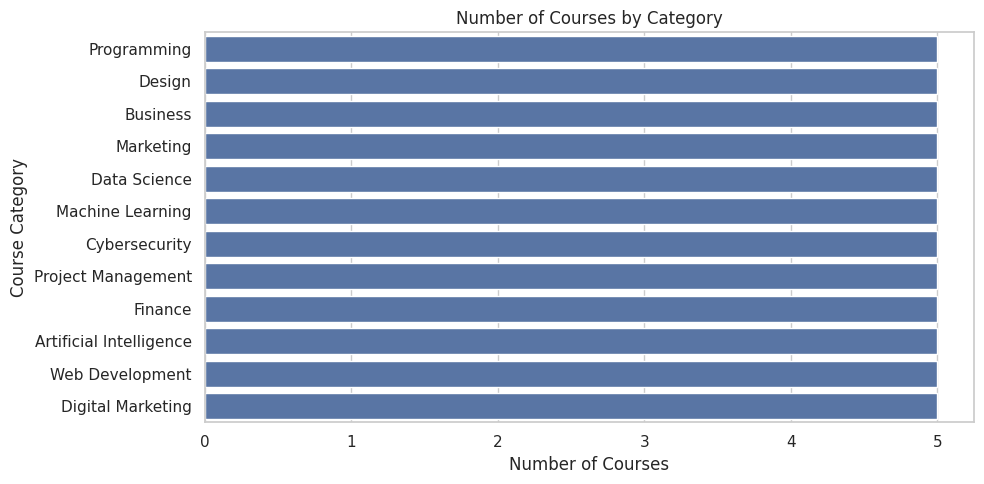

In [ ]:

category_counts = courses["CourseCategory"].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Number of Courses by Category")
plt.xlabel("Number of Courses")
plt.ylabel("Course Category")
plt.tight_layout()
plt.show()


**Exploratory Data Analysis (EDA)**

Age Statistics:


,Age
count,3000.000000
mean,24.974333
std,6.046475
min,15.000000
25%,20.000000
50%,25.000000
75%,30.000000
max,35.000000



Gender Distribution:


,count
Gender,
Female,1520
Male,1480


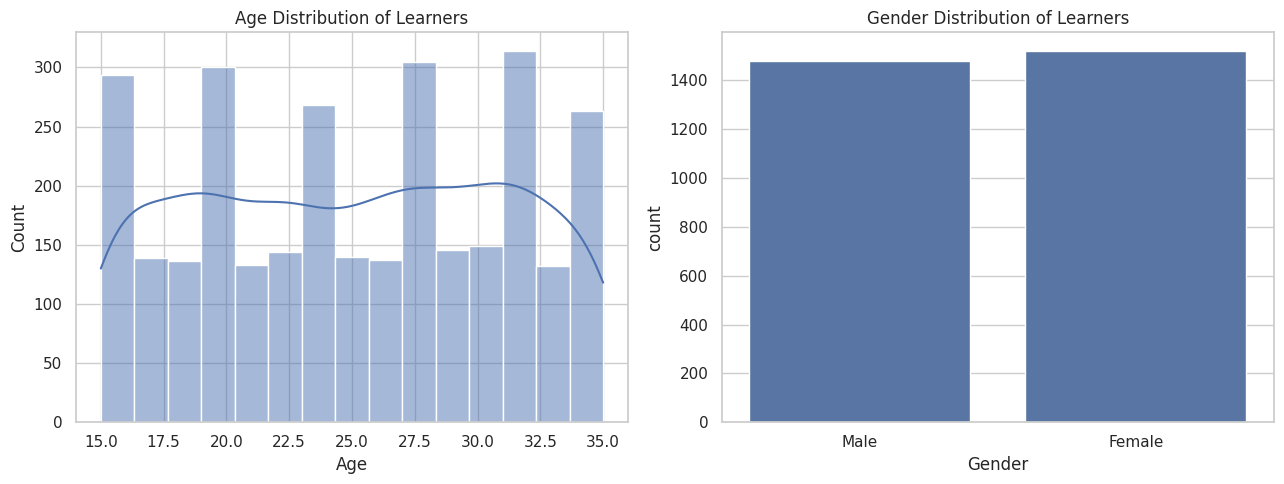

In [ ]:

# Learner demographics
print("Age Statistics:")
display(users["Age"].describe())

print("\nGender Distribution:")
display(users["Gender"].value_counts())

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=users, x="Age", bins=15, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution of Learners")

sns.countplot(data=users, x="Gender", ax=axes[1])
axes[1].set_title("Gender Distribution of Learners")

plt.tight_layout()
plt.show()


Courses by Category:


,count
CourseCategory,
Programming,5
Design,5
Business,5
Marketing,5
Data Science,5
Machine Learning,5
Cybersecurity,5
Project Management,5
Finance,5



Courses by Level:


,count
CourseLevel,
Beginner,21
Advanced,21
Intermediate,18



Courses by Type:


,count
CourseType,
Free,38
Paid,22


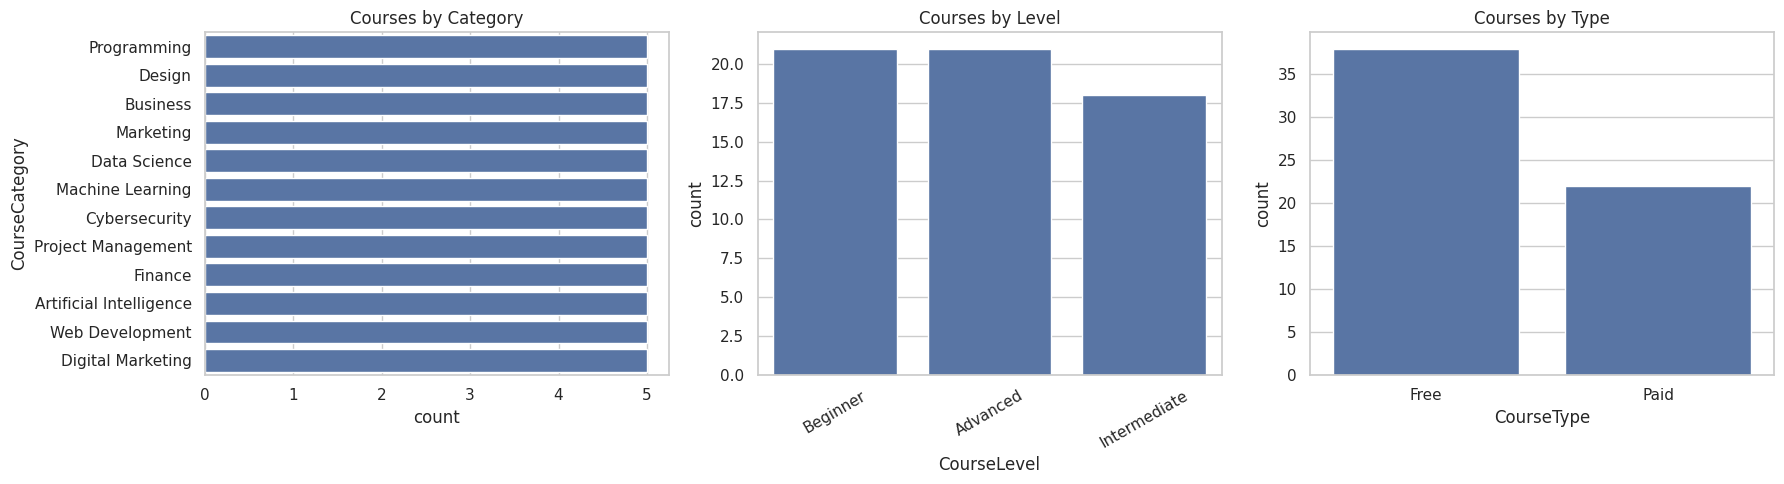

In [ ]:

print("Courses by Category:")
display(courses["CourseCategory"].value_counts())

print("\nCourses by Level:")
display(courses["CourseLevel"].value_counts())

print("\nCourses by Type:")
display(courses["CourseType"].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=courses, y="CourseCategory", ax=axes[0],
              order=courses["CourseCategory"].value_counts().index)
axes[0].set_title("Courses by Category")

sns.countplot(data=courses, x="CourseLevel", ax=axes[1],
              order=courses["CourseLevel"].value_counts().index)
axes[1].set_title("Courses by Level")
axes[1].tick_params(axis="x", rotation=30)

sns.countplot(data=courses, x="CourseType", ax=axes[2],
              order=courses["CourseType"].value_counts().index)
axes[2].set_title("Courses by Type")

plt.tight_layout()
plt.show()


In [ ]:

# Combine transactions with course details
enrollment_data = transactions.merge(
    courses,
    on="CourseID",
    how="left",
    validate="many_to_one"
)

print("Enrollment dataset shape:", enrollment_data.shape)

print("\nTop 10 courses by transaction count:")
display(
    enrollment_data.groupby("CourseName")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("Enrollment Records")
    .reset_index()
)


Enrollment dataset shape: (10000, 14)

Top 10 courses by transaction count:


,CourseName,Enrollment Records
0,Deep Learning,334
1,Natural Language Processing,321
2,Data Analysis with Python,196
3,Social Media Strategy,194
4,Statistical Analysis,192
5,AI Ethics,186
6,Machine Learning Fundamentals,185
7,Investment Strategies,183
8,Corporate Finance,182
9,3D Modeling,180


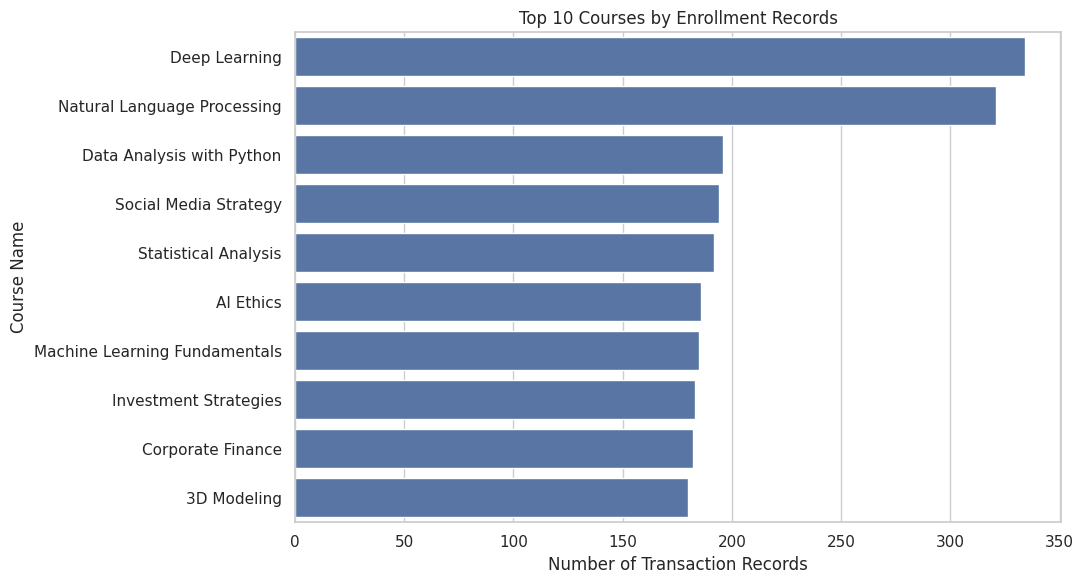

In [ ]:

top_courses = enrollment_data["CourseName"].value_counts().head(10)

plt.figure(figsize=(11, 6))
sns.barplot(x=top_courses.values, y=top_courses.index)

plt.title("Top 10 Courses by Enrollment Records")
plt.xlabel("Number of Transaction Records")
plt.ylabel("Course Name")
plt.tight_layout()
plt.show()


,CourseCategory,Enrollment Records
0,Data Science,916
1,Finance,864
2,Web Development,844
3,Business,833
4,Project Management,829
5,Artificial Intelligence,829
6,Design,827
7,Cybersecurity,819
8,Machine Learning,819
9,Digital Marketing,808


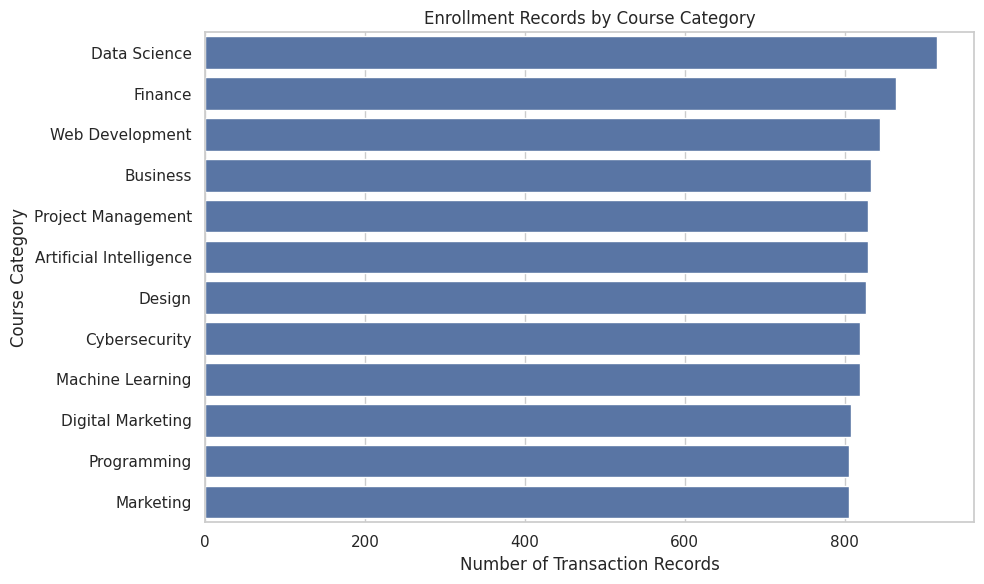

In [ ]:

category_enrollments = (
    enrollment_data.groupby("CourseCategory")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Enrollment Records")
)

display(category_enrollments)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_enrollments,
    x="Enrollment Records",
    y="CourseCategory"
)

plt.title("Enrollment Records by Course Category")
plt.xlabel("Number of Transaction Records")
plt.ylabel("Course Category")
plt.tight_layout()
plt.show()


Transaction Amount Statistics:


,Amount
count,10000.000000
mean,91.132347
std,152.063524
min,0.000000
25%,0.000000
50%,0.000000
75%,119.040000
max,490.900000



Course Rating Statistics:


,CourseRating
count,60.000000
mean,3.097833
std,1.171232
min,1.130000
25%,2.107500
50%,3.065000
75%,4.102500
max,4.940000


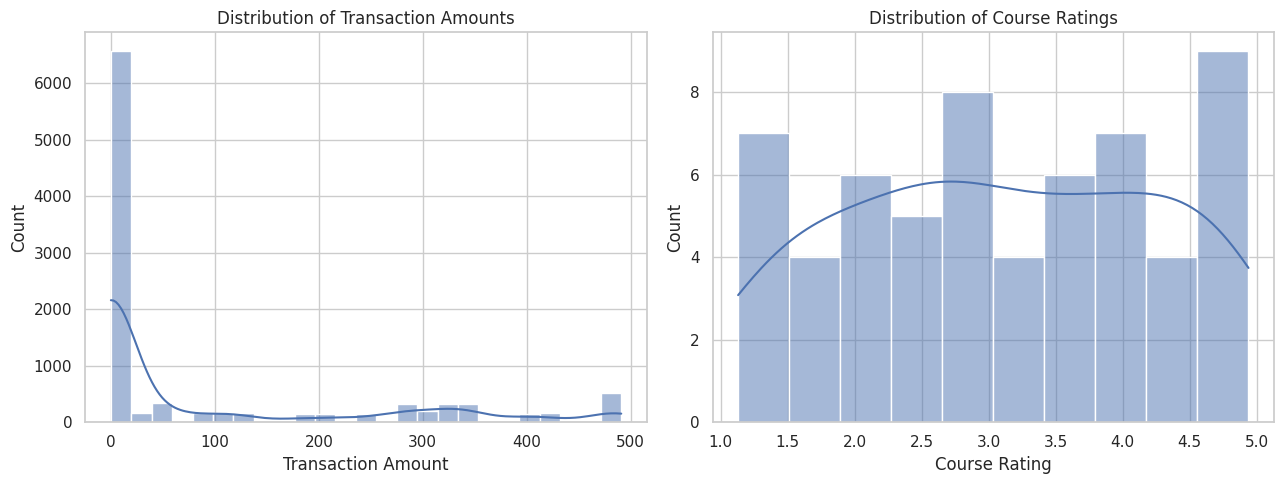

In [ ]:

print("Transaction Amount Statistics:")
display(transactions["Amount"].describe())

print("\nCourse Rating Statistics:")
display(courses["CourseRating"].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=transactions, x="Amount", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Transaction Amounts")
axes[0].set_xlabel("Transaction Amount")

sns.histplot(data=courses, x="CourseRating", bins=10, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Course Ratings")
axes[1].set_xlabel("Course Rating")

plt.tight_layout()
plt.show()


In [ ]:

course_type_summary = (
    enrollment_data.groupby("CourseType")
    .agg(
        Enrollment_Records=("TransactionID", "count"),
        Unique_Learners=("UserID", "nunique"),
        Average_Amount=("Amount", "mean"),
        Average_Course_Rating=("CourseRating", "mean")
    )
    .round(2)
)

display(course_type_summary)


,Enrollment_Records,Unique_Learners,Average_Amount,Average_Course_Rating
CourseType,,,,
Free,6403,2359,0.00,3.21
Paid,3597,1605,253.36,2.96


,Month,Enrollment Records
0,2025-01,833
1,2025-02,766
2,2025-03,857
3,2025-04,831
4,2025-05,825
5,2025-06,899
6,2025-07,826
7,2025-08,844
8,2025-09,870
9,2025-10,762


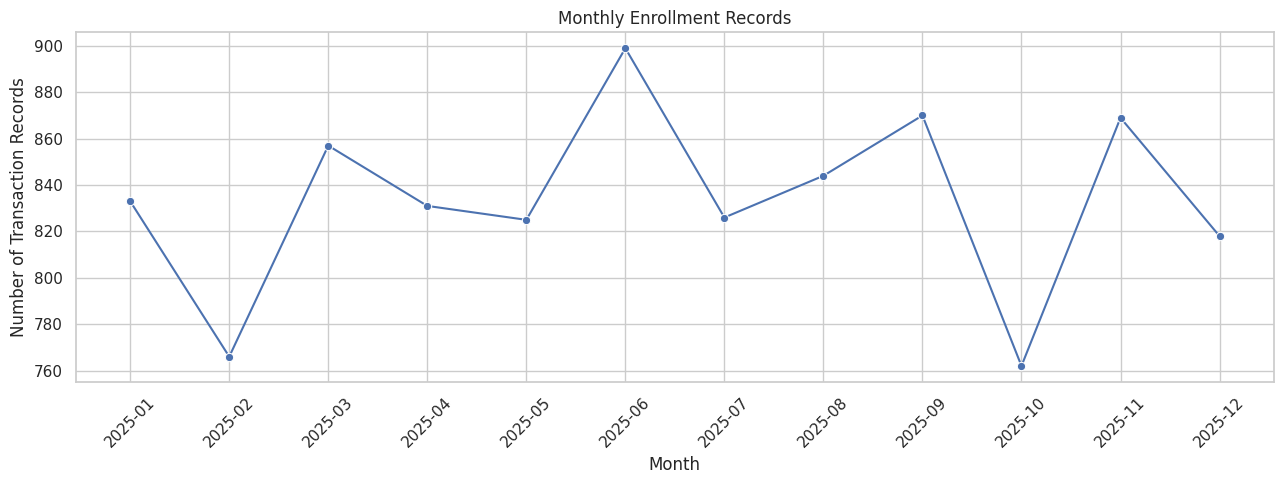

In [ ]:

enrollment_data["Month"] = (
    enrollment_data["TransactionDate"]
    .dt.to_period("M")
    .astype(str)
)

monthly_enrollments = (
    enrollment_data.groupby("Month")
    .size()
    .reset_index(name="Enrollment Records")
)

display(monthly_enrollments)

plt.figure(figsize=(13, 5))
sns.lineplot(
    data=monthly_enrollments,
    x="Month",
    y="Enrollment Records",
    marker="o"
)

plt.title("Monthly Enrollment Records")
plt.xlabel("Month")
plt.ylabel("Number of Transaction Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

learner_summary = (
    enrollment_data.groupby("UserID")
    .agg(
        Total_Enrollments=("TransactionID", "count"),
        Unique_Courses=("CourseID", "nunique"),
        Total_Spending=("Amount", "sum"),
        Average_Transaction_Amount=("Amount", "mean"),
        Categories_Explored=("CourseCategory", "nunique"),
        Average_Course_Rating=("CourseRating", "mean")
    )
    .reset_index()
)

learner_summary["Average_Course_Rating"] = (
    learner_summary["Average_Course_Rating"].round(2)
)

print("Learner profiles created:", len(learner_summary))
display(learner_summary.head(10))

print("\nLearner behavior statistics:")
display(
    learner_summary[
        [
            "Total_Enrollments",
            "Unique_Courses",
            "Total_Spending",
            "Categories_Explored",
            "Average_Course_Rating"
        ]
    ].describe().round(2)
)


Learner profiles created: 3000


,UserID,Total_Enrollments,Unique_Courses,Total_Spending,Average_Transaction_Amount,Categories_Explored,Average_Course_Rating
0,U00001,1,1,394.26,394.260000,1,1.35
1,U00002,1,1,0.00,0.000000,1,2.88
2,U00003,11,11,613.98,55.816364,7,2.89
3,U00004,13,13,982.05,75.542308,8,3.45
4,U00005,2,2,346.71,173.355000,2,2.05
5,U00006,1,1,0.78,0.780000,1,3.89
6,U00007,1,1,0.00,0.000000,1,1.91
7,U00008,1,1,0.00,0.000000,1,4.10
8,U00009,1,1,276.37,276.370000,1,2.72
9,U00010,2,2,326.02,163.010000,2,3.16



Learner behavior statistics:


,Total_Enrollments,Unique_Courses,Total_Spending,Categories_Explored,Average_Course_Rating
count,3000.00,3000.00,3000.00,3000.00,3000.00
mean,3.33,3.33,303.77,2.58,3.13
std,4.35,4.35,482.51,2.73,0.95
min,1.00,1.00,0.00,1.00,1.13
25%,1.00,1.00,0.00,1.00,2.57
50%,1.00,1.00,53.86,1.00,3.12
75%,3.00,3.00,415.51,2.00,3.80
max,16.00,16.00,3054.37,11.00,4.94


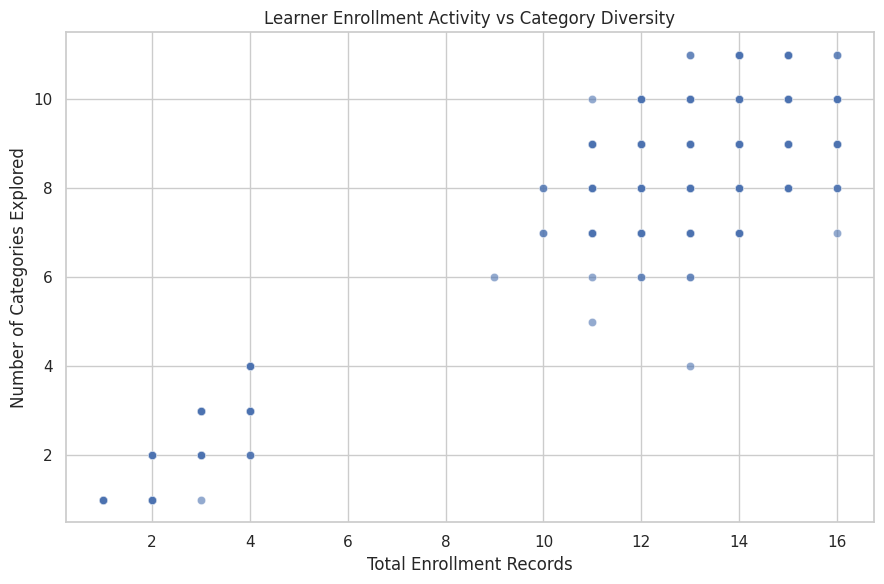

In [ ]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=learner_summary,
    x="Total_Enrollments",
    y="Categories_Explored",
    alpha=0.6
)

plt.title("Learner Enrollment Activity vs Category Diversity")
plt.xlabel("Total Enrollment Records")
plt.ylabel("Number of Categories Explored")
plt.tight_layout()
plt.show()


In [ ]:

learner_summary.to_csv("EduPro_Learner_Summary.csv", index=False)
enrollment_data.to_csv("EduPro_Enrollment_Analysis.csv", index=False)

print("EDA datasets saved successfully!")


EDA datasets saved successfully!


**Data Cleaning and Feature Engineering**

In [ ]:

# Check transaction data quality
print("Missing values in transactions:")
display(transactions.isnull().sum())

print("Duplicate transaction IDs:",
      transactions["TransactionID"].duplicated().sum())

print("Duplicate learner-course pairs:",
      transactions.duplicated(
          subset=["UserID", "CourseID"]
      ).sum())

print("Invalid or negative transaction amounts:",
      (transactions["Amount"] < 0).sum())

print("Invalid course ratings:",
      ((courses["CourseRating"] < 0) |
       (courses["CourseRating"] > 5)).sum())


Missing values in transactions:


,0
TransactionID,0
UserID,0
CourseID,0
TransactionDate,0
Amount,0
PaymentMethod,0
TeacherID,0


Duplicate transaction IDs: 0
Duplicate learner-course pairs: 0
Invalid or negative transaction amounts: 0
Invalid course ratings: 0


In [ ]:

# Create a fresh merged dataset
enrollment_data = transactions.merge(
    courses,
    on="CourseID",
    how="left",
    validate="many_to_one"
)

enrollment_data["TransactionDate"] = pd.to_datetime(
    enrollment_data["TransactionDate"],
    errors="coerce"
)

# Calculate learner-level numerical features
learner_features = (
    enrollment_data.groupby("UserID")
    .agg(
        Total_Enrollments=("TransactionID", "count"),
        Unique_Courses=("CourseID", "nunique"),
        Total_Spending=("Amount", "sum"),
        Average_Spending=("Amount", "mean"),
        Category_Diversity=("CourseCategory", "nunique"),
        Average_Course_Rating=("CourseRating", "mean")
    )
    .reset_index()
)

# Enrollment frequency: transactions per observed month
date_span = (
    enrollment_data.groupby("UserID")["TransactionDate"]
    .agg(First_Enrollment="min", Last_Enrollment="max")
    .reset_index()
)

learner_features = learner_features.merge(
    date_span, on="UserID", how="left"
)

learner_features["Observed_Months"] = (
    (learner_features["Last_Enrollment"].dt.year -
     learner_features["First_Enrollment"].dt.year) * 12
    + (learner_features["Last_Enrollment"].dt.month -
       learner_features["First_Enrollment"].dt.month)
    + 1
)

learner_features["Enrollment_Frequency"] = (
    learner_features["Total_Enrollments"] /
    learner_features["Observed_Months"].clip(lower=1)
)

display(learner_features.head())
print("Learner profiles:", learner_features.shape)


,UserID,Total_Enrollments,Unique_Courses,Total_Spending,Average_Spending,Category_Diversity,Average_Course_Rating,First_Enrollment,Last_Enrollment,Observed_Months,Enrollment_Frequency
0,U00001,1,1,394.26,394.260000,1,1.350000,2025-11-02,2025-11-02,1,1.000000
1,U00002,1,1,0.00,0.000000,1,2.880000,2025-07-15,2025-07-15,1,1.000000
2,U00003,11,11,613.98,55.816364,7,2.889091,2025-01-13,2025-11-16,11,1.000000
3,U00004,13,13,982.05,75.542308,8,3.451538,2025-01-06,2025-11-23,11,1.181818
4,U00005,2,2,346.71,173.355000,2,2.055000,2025-09-11,2025-12-03,4,0.500000


Learner profiles: (3000, 11)


In [ ]:

# Preferred category: category with the most enrollment records
category_counts = (
    enrollment_data.groupby(["UserID", "CourseCategory"])
    .size()
    .reset_index(name="Category_Enrollments")
    .sort_values(
        ["UserID", "Category_Enrollments", "CourseCategory"],
        ascending=[True, False, True]
    )
)

preferred_category = (
    category_counts.drop_duplicates("UserID")
    [["UserID", "CourseCategory"]]
    .rename(columns={"CourseCategory": "Preferred_Category"})
)

# Calculate course-level ratios
level_data = enrollment_data.copy()

level_data["Is_Beginner"] = (
    level_data["CourseLevel"].str.lower() == "beginner"
).astype(int)

level_data["Is_Advanced"] = (
    level_data["CourseLevel"].str.lower() == "advanced"
).astype(int)

level_ratios = (
    level_data.groupby("UserID")
    .agg(
        Beginner_Ratio=("Is_Beginner", "mean"),
        Advanced_Ratio=("Is_Advanced", "mean")
    )
    .reset_index()
)

learner_features = learner_features.merge(
    preferred_category, on="UserID", how="left"
)

learner_features = learner_features.merge(
    level_ratios, on="UserID", how="left"
)

display(
    learner_features[
        [
            "UserID",
            "Total_Enrollments",
            "Category_Diversity",
            "Preferred_Category",
            "Beginner_Ratio",
            "Advanced_Ratio"
        ]
    ].head(10)
)


,UserID,Total_Enrollments,Category_Diversity,Preferred_Category,Beginner_Ratio,Advanced_Ratio
0,U00001,1,1,Cybersecurity,0.000000,0.000000
1,U00002,1,1,Programming,1.000000,0.000000
2,U00003,11,7,Marketing,0.363636,0.363636
3,U00004,13,8,Digital Marketing,0.307692,0.230769
4,U00005,2,2,Programming,0.500000,0.500000
5,U00006,1,1,Machine Learning,0.000000,1.000000
6,U00007,1,1,Cybersecurity,0.000000,0.000000
7,U00008,1,1,Finance,0.000000,0.000000
8,U00009,1,1,Design,0.000000,1.000000
9,U00010,2,2,Artificial Intelligence,0.500000,0.000000


In [ ]:

learner_profiles = users[
    ["UserID", "Age", "Gender"]
].merge(
    learner_features,
    on="UserID",
    how="left",
    validate="one_to_one"
)

print("Final learner profile shape:", learner_profiles.shape)
print("Missing values:")
display(learner_profiles.isnull().sum())

display(learner_profiles.head(10))


Final learner profile shape: (3000, 16)
Missing values:


,0
UserID,0
Age,0
Gender,0
Total_Enrollments,0
Unique_Courses,0
Total_Spending,0
Average_Spending,0
Category_Diversity,0
Average_Course_Rating,0
First_Enrollment,0


,UserID,Age,Gender,Total_Enrollments,Unique_Courses,Total_Spending,Average_Spending,Category_Diversity,Average_Course_Rating,First_Enrollment,Last_Enrollment,Observed_Months,Enrollment_Frequency,Preferred_Category,Beginner_Ratio,Advanced_Ratio
0,U00001,15,Male,1,1,394.26,394.260000,1,1.350000,2025-11-02,2025-11-02,1,1.000000,Cybersecurity,0.000000,0.000000
1,U00002,29,Female,1,1,0.00,0.000000,1,2.880000,2025-07-15,2025-07-15,1,1.000000,Programming,1.000000,0.000000
2,U00003,33,Female,11,11,613.98,55.816364,7,2.889091,2025-01-13,2025-11-16,11,1.000000,Marketing,0.363636,0.363636
3,U00004,23,Female,13,13,982.05,75.542308,8,3.451538,2025-01-06,2025-11-23,11,1.181818,Digital Marketing,0.307692,0.230769
4,U00005,21,Male,2,2,346.71,173.355000,2,2.055000,2025-09-11,2025-12-03,4,0.500000,Programming,0.500000,0.500000
5,U00006,21,Male,1,1,0.78,0.780000,1,3.890000,2025-11-19,2025-11-19,1,1.000000,Machine Learning,0.000000,1.000000
6,U00007,24,Male,1,1,0.00,0.000000,1,1.910000,2025-03-08,2025-03-08,1,1.000000,Cybersecurity,0.000000,0.000000
7,U00008,33,Female,1,1,0.00,0.000000,1,4.100000,2025-07-30,2025-07-30,1,1.000000,Finance,0.000000,0.000000
8,U00009,20,Female,1,1,276.37,276.370000,1,2.720000,2025-06-19,2025-06-19,1,1.000000,Design,0.000000,1.000000
9,U00010,34,Female,2,2,326.02,163.010000,2,3.165000,2025-08-02,2025-10-01,3,0.666667,Artificial Intelligence,0.500000,0.000000


In [ ]:

from sklearn.preprocessing import StandardScaler

clustering_features = [
    "Total_Enrollments",
    "Unique_Courses",
    "Total_Spending",
    "Average_Spending",
    "Category_Diversity",
    "Average_Course_Rating",
    "Enrollment_Frequency",
    "Beginner_Ratio",
    "Advanced_Ratio"
]

# Replace missing numeric values with the respective median
X = learner_profiles[clustering_features].copy()

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Clustering matrix shape:", X_scaled.shape)
print("All features standardized successfully!")


Clustering matrix shape: (3000, 9)
All features standardized successfully!


In [ ]:

learner_profiles.to_csv(
    "EduPro_Learner_Profiles.csv",
    index=False
)

print("Learner profiles saved successfully!")


Learner profiles saved successfully!


**Student Segmentation Using K-Means Clustering**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


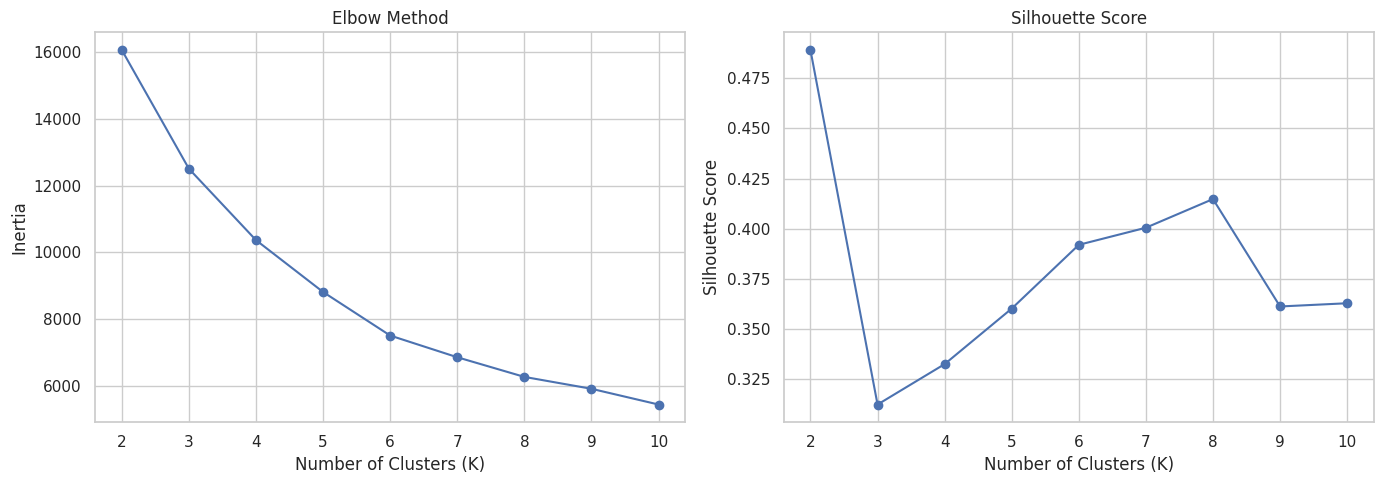

,K,Inertia,Silhouette_Score
0,2,16069.2965,0.4891
1,3,12508.4263,0.3123
2,4,10366.8865,0.3324
3,5,8811.3939,0.3601
4,6,7505.0087,0.3919
5,7,6854.0751,0.4005
6,8,6264.6807,0.4148
7,9,5907.8635,0.3612
8,10,5435.8413,0.3628


In [ ]:

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

# Plot both evaluation methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values), inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(
    list(k_values), silhouette_values,
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

# Display the scores
evaluation_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

display(evaluation_results.round(4))


In [ ]:

best_k = int(
    evaluation_results.loc[
        evaluation_results["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print("Best K by silhouette score:", best_k)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

learner_profiles["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nLearners in each cluster:")
display(
    learner_profiles["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of Learners")
    .to_frame()
)


Best K by silhouette score: 2

Learners in each cluster:


,Number of Learners
Cluster,
0,2546
1,454


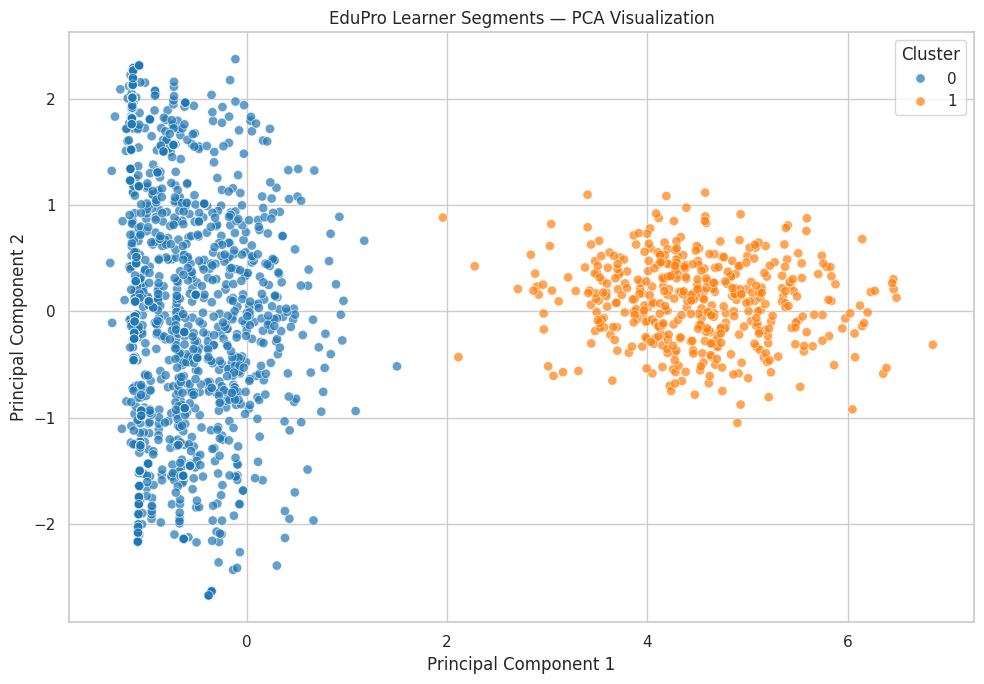

Variance explained by two components: 61.0 %


In [ ]:

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

cluster_plot = pd.DataFrame({
    "PCA1": pca_data[:, 0],
    "PCA2": pca_data[:, 1],
    "Cluster": learner_profiles["Cluster"].astype(str).values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cluster_plot,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=45
)

plt.title("EduPro Learner Segments — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [ ]:

cluster_profile = (
    learner_profiles.groupby("Cluster")
    .agg(
        Learner_Count=("UserID", "count"),
        Avg_Enrollments=("Total_Enrollments", "mean"),
        Avg_Unique_Courses=("Unique_Courses", "mean"),
        Avg_Category_Diversity=("Category_Diversity", "mean"),
        Avg_Total_Spending=("Total_Spending", "mean"),
        Avg_Course_Rating=("Average_Course_Rating", "mean"),
        Avg_Enrollment_Frequency=("Enrollment_Frequency", "mean"),
        Avg_Beginner_Ratio=("Beginner_Ratio", "mean"),
        Avg_Advanced_Ratio=("Advanced_Ratio", "mean")
    )
    .round(2)
)

cluster_profile["Learner_Percentage"] = (
    cluster_profile["Learner_Count"]
    / len(learner_profiles) * 100
).round(2)

display(cluster_profile)


,Learner_Count,Avg_Enrollments,Avg_Unique_Courses,Avg_Category_Diversity,Avg_Total_Spending,Avg_Course_Rating,Avg_Enrollment_Frequency,Avg_Beginner_Ratio,Avg_Advanced_Ratio,Learner_Percentage
Cluster,,,,,,,,,,
0,2546,1.54,1.54,1.48,135.38,3.14,0.86,0.35,0.35,84.87
1,454,13.41,13.41,8.73,1248.13,3.11,1.21,0.36,0.34,15.13


In [ ]:

print("Most common preferred category in each cluster:")

display(
    learner_profiles.groupby("Cluster")["Preferred_Category"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
    .rename("Most Common Preferred Category")
    .to_frame()
)

print("Gender distribution by cluster:")
display(
    pd.crosstab(
        learner_profiles["Cluster"],
        learner_profiles["Gender"],
        normalize="index"
    ).mul(100).round(2)
)


Most common preferred category in each cluster:


,Most Common Preferred Category
Cluster,
0,Artificial Intelligence
1,Artificial Intelligence


Gender distribution by cluster:


Gender,Female,Male
Cluster,,
0,50.67,49.33
1,50.66,49.34


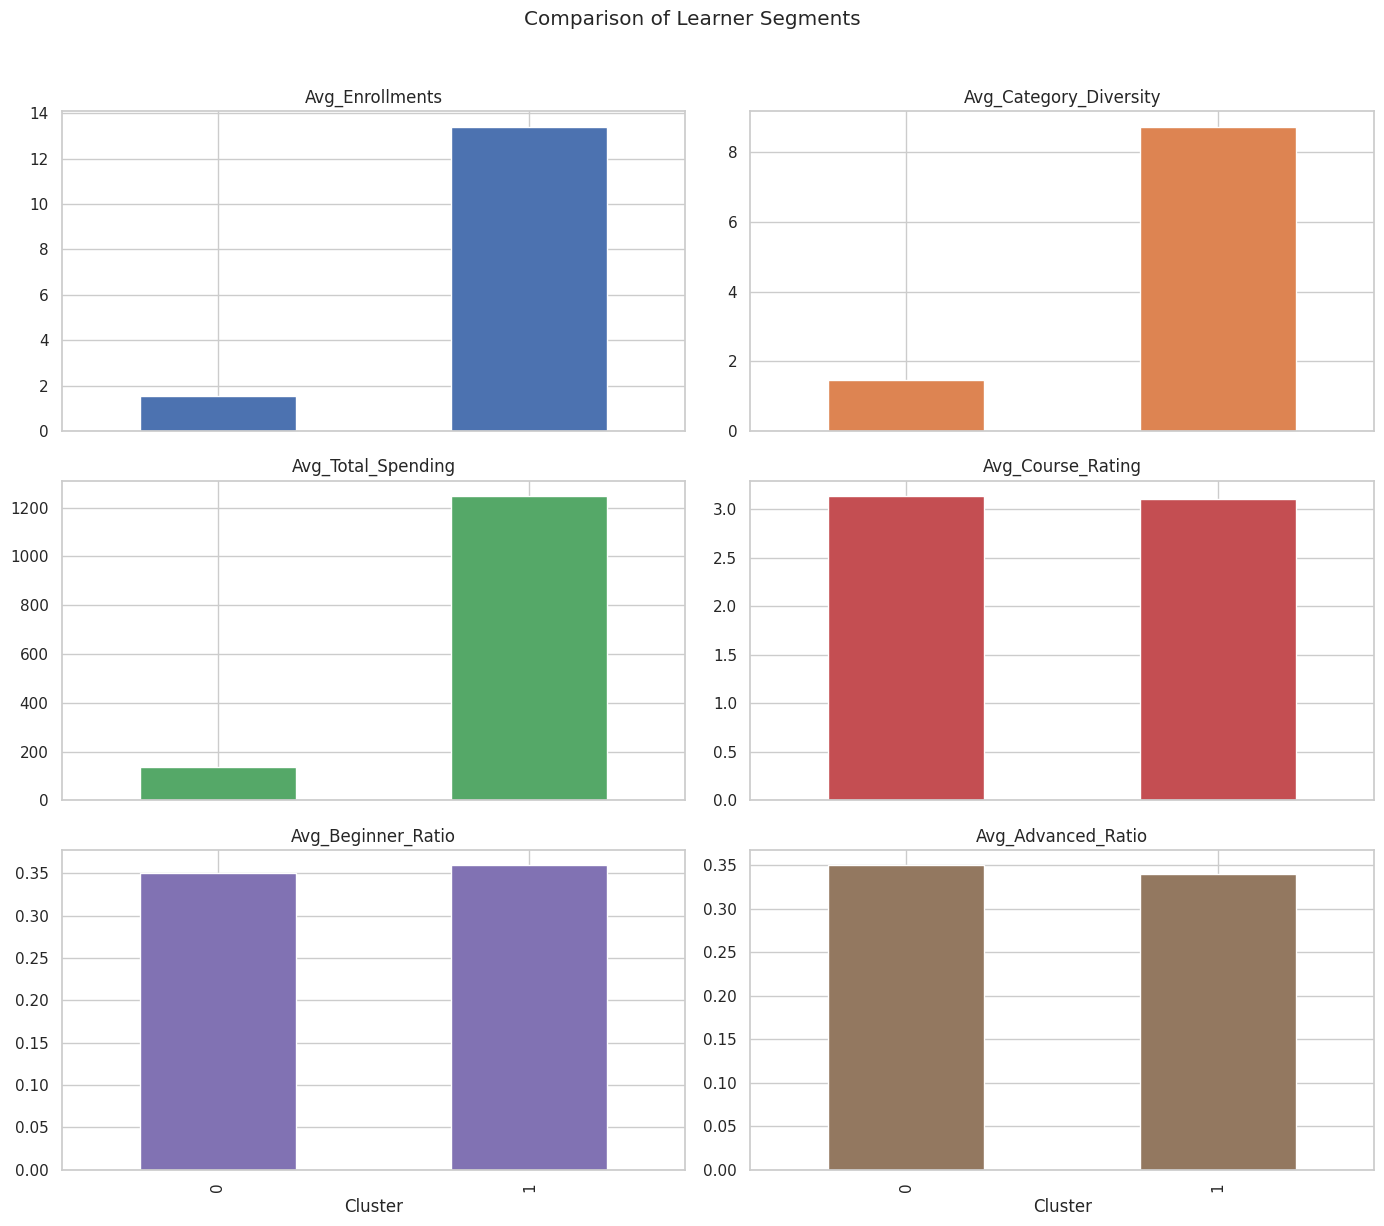

In [ ]:

profile_columns = [
    "Avg_Enrollments",
    "Avg_Category_Diversity",
    "Avg_Total_Spending",
    "Avg_Course_Rating",
    "Avg_Beginner_Ratio",
    "Avg_Advanced_Ratio"
]

cluster_profile[profile_columns].plot(
    kind="bar",
    subplots=True,
    layout=(3, 2),
    figsize=(14, 12),
    legend=False
)

plt.suptitle("Comparison of Learner Segments", y=1.02)
plt.tight_layout()
plt.show()


In [ ]:

learner_profiles.to_csv(
    "EduPro_Learner_Segments.csv",
    index=False
)

cluster_profile.to_csv(
    "EduPro_Cluster_Profiles.csv"
)

print("Segmentation results saved successfully!")


Segmentation results saved successfully!


**Personalized Course Recommendation System for EduPro**

In [ ]:

# Add the learner's cluster to each transaction
recommendation_data = transactions.merge(
    learner_profiles[["UserID", "Cluster"]],
    on="UserID",
    how="left",
    validate="many_to_one"
).merge(
    courses,
    on="CourseID",
    how="left",
    validate="many_to_one"
)

print("Recommendation data shape:", recommendation_data.shape)

print("\nAvailable course categories:")
print(sorted(courses["CourseCategory"].dropna().unique()))

print("\nAvailable course levels:")
print(sorted(courses["CourseLevel"].dropna().unique()))

print("\nLearners available:", learner_profiles["UserID"].nunique())


Recommendation data shape: (10000, 15)

Available course categories:
['Artificial Intelligence', 'Business', 'Cybersecurity', 'Data Science', 'Design', 'Digital Marketing', 'Finance', 'Machine Learning', 'Marketing', 'Programming', 'Project Management', 'Web Development']

Available course levels:
['Advanced', 'Beginner', 'Intermediate']

Learners available: 3000


In [ ]:

cluster_course_counts = (
    recommendation_data
    .groupby(["Cluster", "CourseID"])
    .size()
    .reset_index(name="Cluster_Enrollments")
)

# Calculate total enrollments within each cluster
cluster_totals = (
    cluster_course_counts
    .groupby("Cluster")["Cluster_Enrollments"]
    .transform("sum")
)

# Calculate course popularity within each cluster
cluster_course_counts["Cluster_Popularity"] = (
    cluster_course_counts["Cluster_Enrollments"] / cluster_totals
)

# Display the results
display(
    cluster_course_counts.sort_values(
        ["Cluster", "Cluster_Enrollments"],
        ascending=[True, False]
    ).head(10)
)


,Cluster,CourseID,Cluster_Enrollments,Cluster_Popularity
41,0,CR00042,86,0.021972
9,0,CR00010,76,0.019417
34,0,CR00035,76,0.019417
6,0,CR00007,75,0.019162
13,0,CR00014,74,0.018906
20,0,CR00021,74,0.018906
24,0,CR00025,74,0.018906
8,0,CR00009,73,0.018651
22,0,CR00023,73,0.018651
53,0,CR00054,73,0.018651


In [ ]:

cluster_course_counts = (
    recommendation_data.groupby(["Cluster", "CourseID"])
    .size()
    .reset_index(name="Cluster_Enrollments")
)

cluster_totals = cluster_course_counts.groupby(
    "Cluster"
)["Cluster_Enrollments"].transform("sum")

cluster_course_counts["Cluster_Popularity"] = (
    cluster_course_counts["Cluster_Enrollments"] / cluster_totals
)

display(cluster_course_counts.head())


,Cluster,CourseID,Cluster_Enrollments,Cluster_Popularity
0,0,CR00001,55,0.014052
1,0,CR00002,51,0.013030
2,0,CR00003,65,0.016607
3,0,CR00004,62,0.015841
4,0,CR00005,67,0.017118


In [ ]:

def recommend_courses(user_id, top_n=5, category=None, level=None):
    # Find the selected learner
    learner = learner_profiles[
        learner_profiles["UserID"] == user_id
    ]

    if learner.empty:
        raise ValueError("Learner ID not found.")

    cluster = learner.iloc[0]["Cluster"]

    # Get the learner's previous transactions
    history = recommendation_data[
        recommendation_data["UserID"] == user_id
    ]

    seen_courses = set(history["CourseID"])

    # Candidate courses: exclude previously enrolled courses
    candidates = courses[
        ~courses["CourseID"].isin(seen_courses)
    ].copy()

    # Optional filters
    if category is not None:
        candidates = candidates[
            candidates["CourseCategory"] == category
        ]

    if level is not None:
        candidates = candidates[
            candidates["CourseLevel"] == level
        ]

    if candidates.empty:
        return pd.DataFrame(
            columns=[
                "CourseID", "CourseName", "CourseCategory",
                "CourseLevel", "CourseRating", "Recommendation_Score"
            ]
        )

    # Category preference based on learner history
    category_preferences = history[
        "CourseCategory"
    ].value_counts(normalize=True)

    candidates["Category_Score"] = (
        candidates["CourseCategory"]
        .map(category_preferences)
        .fillna(0)
    )

    # Course-level preference based on learner history
    level_preferences = history[
        "CourseLevel"
    ].value_counts(normalize=True)

    candidates["Level_Score"] = (
        candidates["CourseLevel"]
        .map(level_preferences)
        .fillna(0)
    )

    # Popularity among learners in the same cluster
    popularity = cluster_course_counts[
        cluster_course_counts["Cluster"] == cluster
    ][["CourseID", "Cluster_Popularity"]]

    candidates = candidates.merge(
        popularity,
        on="CourseID",
        how="left",
        validate="one_to_one"
    )

    candidates["Cluster_Popularity"] = (
        candidates["Cluster_Popularity"].fillna(0)
    )

    # Normalize popularity relative to the most popular
    max_popularity = candidates["Cluster_Popularity"].max()

    if max_popularity > 0:
        candidates["Popularity_Score"] = (
            candidates["Cluster_Popularity"] / max_popularity
        )
    else:
        candidates["Popularity_Score"] = 0

    # Normalize ratings to a 0-1 scale
    candidates["Rating_Score"] = (
        pd.to_numeric(candidates["CourseRating"], errors="coerce")
        .fillna(0)
        .clip(0, 5) / 5
    )

    # Weighted recommendation score
    candidates["Recommendation_Score"] = (
        0.40 * candidates["Category_Score"]
        + 0.20 * candidates["Level_Score"]
        + 0.25 * candidates["Popularity_Score"]
        + 0.15 * candidates["Rating_Score"]
    )

    # Return the highest-ranked courses
    result = candidates.sort_values(
        ["Recommendation_Score", "CourseRating"],
        ascending=False
    ).head(top_n)

    return result[
        [
            "CourseID",
            "CourseName",
            "CourseCategory",
            "CourseLevel",
            "CourseType",
            "CoursePrice",
            "CourseRating",
            "Recommendation_Score"
        ]
    ].reset_index(drop=True)


In [ ]:

# Select the first learner in the profiles dataset
sample_user_id = learner_profiles.iloc[0]["UserID"]

print("Selected learner:", sample_user_id)

display(
    learner_profiles.loc[
        learner_profiles["UserID"] == sample_user_id,
        [
            "UserID",
            "Cluster",
            "Total_Enrollments",
            "Preferred_Category",
            "Category_Diversity",
            "Beginner_Ratio",
            "Advanced_Ratio"
        ]
    ]
)

print("\nPersonalized course recommendations:")

display(
    recommend_courses(
        user_id=sample_user_id,
        top_n=5
    )
)


Selected learner: U00001


,UserID,Cluster,Total_Enrollments,Preferred_Category,Category_Diversity,Beginner_Ratio,Advanced_Ratio
0,U00001,0,1,Cybersecurity,1,0.0,0.0



Personalized course recommendations:


,CourseID,CourseName,CourseCategory,CourseLevel,CourseType,CoursePrice,CourseRating,Recommendation_Score
0,CR00033,Cybersecurity Fundamentals,Cybersecurity,Intermediate,Free,0.0,3.93,0.921388
1,CR00031,Network Security,Cybersecurity,Intermediate,Free,0.0,1.91,0.860788
2,CR00035,Cyber Threat Intelligence,Cybersecurity,Beginner,Free,0.0,4.94,0.769130
3,CR00032,Ethical Hacking,Cybersecurity,Advanced,Free,0.0,2.38,0.674888
4,CR00042,Investment Strategies,Finance,Intermediate,Free,0.0,4.10,0.573000


In [ ]:

# Recommend only courses from a selected category
display(
    recommend_courses(
        user_id=sample_user_id,
        top_n=5,
        category="Programming"
    )
)

# Recommend only beginner-level courses
display(
    recommend_courses(
        user_id=sample_user_id,
        top_n=5,
        level="Beginner"
    )
)


,CourseID,CourseName,CourseCategory,CourseLevel,CourseType,CoursePrice,CourseRating,Recommendation_Score
0,CR00002,Java Programming,Programming,Intermediate,Free,0.00,2.43,0.463199
1,CR00003,C++ for Beginners,Programming,Beginner,Free,0.00,3.85,0.358037
2,CR00001,Python Basics,Programming,Beginner,Paid,472.28,4.74,0.347424
3,CR00004,Advanced Python,Programming,Beginner,Free,0.00,2.88,0.317743
4,CR00005,Full Stack Development,Programming,Beginner,Free,0.00,1.28,0.288400


,CourseID,CourseName,CourseCategory,CourseLevel,CourseType,CoursePrice,CourseRating,Recommendation_Score
0,CR00035,Cyber Threat Intelligence,Cybersecurity,Beginner,Free,0.00,4.94,0.798200
1,CR00009,Web Design Fundamentals,Design,Beginner,Free,0.00,4.51,0.375432
2,CR00050,Computer Vision,Artificial Intelligence,Beginner,Paid,490.90,4.55,0.373342
3,CR00058,Social Media Strategy,Digital Marketing,Beginner,Free,0.00,4.44,0.370042
4,CR00025,Statistical Analysis,Data Science,Beginner,Paid,299.57,3.74,0.355621


In [ ]:

test_recommendations = recommend_courses(
    user_id=sample_user_id,
    top_n=5
)

previously_enrolled = set(
    transactions.loc[
        transactions["UserID"] == sample_user_id,
        "CourseID"
    ]
)

recommended_ids = set(test_recommendations["CourseID"])

print(
    "Previously enrolled courses excluded:",
    recommended_ids.isdisjoint(previously_enrolled)
)

print(
    "Duplicate recommendations:",
    test_recommendations["CourseID"].duplicated().sum()
)

print(
    "Number of recommendations returned:",
    len(test_recommendations)
)


Previously enrolled courses excluded: True
Duplicate recommendations: 0
Number of recommendations returned: 5


In [ ]:

# Generate recommendations for every learner
all_recommendations = []

for user_id in learner_profiles["UserID"]:
    recs = recommend_courses(user_id, top_n=5)

    if not recs.empty:
        recs = recs.copy()
        recs["UserID"] = user_id
        all_recommendations.append(recs)

if all_recommendations:
    recommendations_df = pd.concat(
        all_recommendations,
        ignore_index=True
    )

    recommendations_df.to_csv(
        "EduPro_Personalized_Recommendations.csv",
        index=False
    )

    print("Recommendations generated:",
          len(recommendations_df))

    display(recommendations_df.head(10))
else:
    recommendations_df = pd.DataFrame()
    print("No eligible recommendations were generated.")


Recommendations generated: 15000


,CourseID,CourseName,CourseCategory,CourseLevel,CourseType,CoursePrice,CourseRating,Recommendation_Score,UserID
0,CR00033,Cybersecurity Fundamentals,Cybersecurity,Intermediate,Free,0.00,3.93,0.921388,U00001
1,CR00031,Network Security,Cybersecurity,Intermediate,Free,0.00,1.91,0.860788,U00001
2,CR00035,Cyber Threat Intelligence,Cybersecurity,Beginner,Free,0.00,4.94,0.769130,U00001
3,CR00032,Ethical Hacking,Cybersecurity,Advanced,Free,0.00,2.38,0.674888,U00001
4,CR00042,Investment Strategies,Finance,Intermediate,Free,0.00,4.10,0.573000,U00001
5,CR00003,C++ for Beginners,Programming,Beginner,Free,0.00,3.85,0.904453,U00002
6,CR00001,Python Basics,Programming,Beginner,Paid,472.28,4.74,0.902084,U00002
7,CR00005,Full Stack Development,Programming,Beginner,Free,0.00,1.28,0.833167,U00002
8,CR00002,Java Programming,Programming,Intermediate,Free,0.00,2.43,0.621156,U00002
9,CR00035,Cyber Threat Intelligence,Cybersecurity,Beginner,Free,0.00,4.94,0.569130,U00002


**Model Evaluation**

In [ ]:

from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(X_scaled, learner_profiles["Cluster"])
final_inertia = kmeans.inertia_

print("Clustering Model Evaluation")
print("---------------------------")
print(f"Number of clusters: {best_k}")
print(f"Silhouette Score: {final_silhouette:.4f}")
print(f"Inertia: {final_inertia:.2f}")


Clustering Model Evaluation
---------------------------
Number of clusters: 2
Silhouette Score: 0.4891
Inertia: 16069.30


In [ ]:

import pandas as pd
import numpy as np

# Check the recommendations generated earlier
test_user_id = learner_profiles.iloc[0]["UserID"]

test_recs = recommend_courses(user_id=test_user_id, top_n=5)

previous_courses = set(
    transactions.loc[
        transactions["UserID"] == test_user_id, "CourseID"
    ]
)

recommended_courses = set(test_recs["CourseID"])

print("Recommendation Evaluation")
print("-------------------------")
print("Recommendations returned:", len(test_recs))
print(
    "Previously enrolled courses excluded:",
    recommended_courses.isdisjoint(previous_courses)
)
print(
    "Duplicate recommendations:",
    test_recs["CourseID"].duplicated().sum()
)

display(test_recs)


Recommendation Evaluation
-------------------------
Recommendations returned: 5
Previously enrolled courses excluded: True
Duplicate recommendations: 0


,CourseID,CourseName,CourseCategory,CourseLevel,CourseType,CoursePrice,CourseRating,Recommendation_Score
0,CR00033,Cybersecurity Fundamentals,Cybersecurity,Intermediate,Free,0.0,3.93,0.921388
1,CR00031,Network Security,Cybersecurity,Intermediate,Free,0.0,1.91,0.860788
2,CR00035,Cyber Threat Intelligence,Cybersecurity,Beginner,Free,0.0,4.94,0.769130
3,CR00032,Ethical Hacking,Cybersecurity,Advanced,Free,0.0,2.38,0.674888
4,CR00042,Investment Strategies,Finance,Intermediate,Free,0.0,4.10,0.573000


**Install the required libraries**

In [ ]:
!pip install streamlit pandas matplotlib seaborn scikit-learn

In [ ]:
learner_profiles.to_csv(
    "EduPro_Learner_Profiles.csv", index=False
)

recommendations_df.to_csv(
    "EduPro_Personalized_Recommendations.csv", index=False
)

courses.to_csv(
    "EduPro_Courses.csv", index=False
)

evaluation_results.to_csv(
    "EduPro_Model_Evaluation.csv", index=False
)

print("All dashboard files saved successfully!")

All dashboard files saved successfully!


In [ ]:
transactions.to_csv("EduPro_Transactions.csv", index=False)
print("Transactions file saved!")

Transactions file saved!


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="EduPro Analytics",
    page_icon="🎓",
    layout="wide"
)

# Load project datasets
@st.cache_data
def load_data():
    learners = pd.read_csv("EduPro_Learner_Profiles.csv")
    courses = pd.read_csv("EduPro_Courses.csv")
    transactions = pd.read_csv("EduPro_Transactions.csv")
    recommendations = pd.read_csv(
        "EduPro_Personalized_Recommendations.csv"
    )
    evaluation = pd.read_csv("EduPro_Model_Evaluation.csv")

    return learners, courses, transactions, recommendations, evaluation

learners, courses, transactions, recommendations, evaluation = load_data()

st.title("🎓 EduPro: Student Segmentation and Course Recommendations")
st.write("A data-driven platform for understanding learners and personalizing course suggestions.")

# Sidebar navigation
page = st.sidebar.radio(
    "Navigation",
    [
        "Overview",
        "Learner Explorer",
        "Cluster Analysis",
        "Course Recommendations",
        "Model Evaluation"
    ]
)

# OVERVIEW
if page == "Overview":

    st.header("Platform Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Learners", len(learners))
    col2.metric("Total Courses", len(courses))
    col3.metric("Total Enrollments", len(transactions))
    col4.metric(
        "Learner Segments",
        learners["Cluster"].nunique()
    )

    st.subheader("Course Category Distribution")

    category_counts = courses["CourseCategory"].value_counts()

    fig, ax = plt.subplots()
    category_counts.plot(kind="bar", ax=ax)
    ax.set_xlabel("Course Category")
    ax.set_ylabel("Number of Courses")
    ax.tick_params(axis="x", rotation=45)

    st.pyplot(fig)

    st.subheader("Learner Profile Preview")
    st.dataframe(learners.head(10), use_container_width=True)


# LEARNER EXPLORER
elif page == "Learner Explorer":

    st.header("Learner Explorer")

    user_id = st.selectbox(
        "Select Learner ID",
        learners["UserID"].tolist()
    )

    learner = learners[learners["UserID"] == user_id]

    if not learner.empty:

        st.subheader("Learner Information")
        st.dataframe(learner, use_container_width=True)

        st.metric(
            "Assigned Cluster",
            int(learner.iloc[0]["Cluster"])
        )

        st.metric(
            "Total Enrollments",
            int(learner.iloc[0]["Total_Enrollments"])
        )

        st.metric(
            "Total Spending",
            round(learner.iloc[0]["Total_Spending"], 2)
        )

        st.write(
            "Preferred Category:",
            learner.iloc[0]["Preferred_Category"]
        )


# CLUSTER ANALYSIS
elif page == "Cluster Analysis":

    st.header("Learner Cluster Analysis")

    cluster_summary = learners.groupby("Cluster").agg(
        Learners=("UserID", "count"),
        Average_Enrollments=("Total_Enrollments", "mean"),
        Average_Spending=("Total_Spending", "mean"),
        Average_Rating=("Average_Course_Rating", "mean"),
        Category_Diversity=("Category_Diversity", "mean")
    ).reset_index()

    st.subheader("Cluster Comparison")
    st.dataframe(cluster_summary, use_container_width=True)

    st.subheader("Learners in Each Cluster")

    cluster_counts = learners["Cluster"].value_counts().sort_index()

    fig, ax = plt.subplots()
    cluster_counts.plot(kind="bar", ax=ax)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Number of Learners")

    st.pyplot(fig)

    st.subheader("Average Spending by Cluster")

    fig, ax = plt.subplots()
    cluster_summary.plot(
        x="Cluster",
        y="Average_Spending",
        kind="bar",
        ax=ax,
        legend=False
    )
    ax.set_ylabel("Average Spending")

    st.pyplot(fig)


# COURSE RECOMMENDATIONS
elif page == "Course Recommendations":

    st.header("Personalized Course Recommendations")

    user_id = st.selectbox(
        "Choose Learner ID",
        learners["UserID"].tolist(),
        key="recommendation_user"
    )

    learner_recommendations = recommendations[
        recommendations["UserID"] == user_id
    ]

    if not learner_recommendations.empty:

        st.subheader("Recommended Courses")

        st.dataframe(
            learner_recommendations[
                [
                    "CourseID",
                    "CourseName",
                    "CourseCategory",
                    "CourseLevel",
                    "CourseRating",
                    "Recommendation_Score"
                ]
            ],
            use_container_width=True
        )

    else:
        st.warning("No recommendations available for this learner.")


# MODEL EVALUATION
elif page == "Model Evaluation":

    st.header("Model Evaluation Results")

    st.dataframe(evaluation, use_container_width=True)

    st.write(
        "The silhouette score indicates cluster separation. "
        "The historical course recovery rate measures how often "
        "the recommendation system retrieves a held-out course "
        "among its top five suggestions."
    )

st.sidebar.markdown("---")
st.sidebar.write("EduPro Student Analytics Project")


Writing app.py


In [ ]:
from google.colab import files

files.download("app.py")
files.download("EduPro_Learner_Profiles.csv")
files.download("EduPro_Courses.csv")
files.download("EduPro_Transactions.csv")
files.download("EduPro_Personalized_Recommendations.csv")
files.download("EduPro_Model_Evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
pip install streamlit pandas matplotlib

In [ ]:
!streamlit run app.py



2026-11-06 08:38:29.123 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.124.200.167:8501

  Stopping...
  Stopping...


**Generate the final project summary**

In [ ]:

import pandas as pd
import numpy as np

# Check whether the required variables exist
required_variables = [
    "learner_profiles",
    "courses",
    "transactions"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    print("Missing variables:", missing)
    print("Please execute the earlier project steps first.")
else:
    print("EDUPRO PROJECT SUMMARY")
    print("======================")

    print("Total Learners:", len(learner_profiles))
    print("Total Courses:", len(courses))
    print("Total Transactions:", len(transactions))
    print("Number of Learner Clusters:",
          learner_profiles["Cluster"].nunique())

    print("\nLearner Profile Preview:")
    display(learner_profiles.head())

    print("\nCourse Dataset Preview:")
    display(courses.head())

    print("\nTransaction Dataset Preview:")
    display(transactions.head())


EDUPRO PROJECT SUMMARY
Total Learners: 3000
Total Courses: 60
Total Transactions: 10000
Number of Learner Clusters: 2

Learner Profile Preview:


,UserID,Age,Gender,Total_Enrollments,Unique_Courses,Total_Spending,Average_Spending,Category_Diversity,Average_Course_Rating,First_Enrollment,Last_Enrollment,Observed_Months,Enrollment_Frequency,Preferred_Category,Beginner_Ratio,Advanced_Ratio,Cluster
0,U00001,15,Male,1,1,394.26,394.260000,1,1.350000,2025-11-02,2025-11-02,1,1.000000,Cybersecurity,0.000000,0.000000,0
1,U00002,29,Female,1,1,0.00,0.000000,1,2.880000,2025-07-15,2025-07-15,1,1.000000,Programming,1.000000,0.000000,0
2,U00003,33,Female,11,11,613.98,55.816364,7,2.889091,2025-01-13,2025-11-16,11,1.000000,Marketing,0.363636,0.363636,1
3,U00004,23,Female,13,13,982.05,75.542308,8,3.451538,2025-01-06,2025-11-23,11,1.181818,Digital Marketing,0.307692,0.230769,1
4,U00005,21,Male,2,2,346.71,173.355000,2,2.055000,2025-09-11,2025-12-03,4,0.500000,Programming,0.500000,0.500000,0



Course Dataset Preview:


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28



Transaction Dataset Preview:


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2025-06-02,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,2025-08-10,0.0,PayPal,TC00042


In [ ]:

cluster_summary = learner_profiles.groupby("Cluster").agg(
    Total_Learners=("UserID", "count"),
    Average_Enrollments=("Total_Enrollments", "mean"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Course_Rating=("Average_Course_Rating", "mean"),
    Average_Category_Diversity=("Category_Diversity", "mean"),
    Average_Beginner_Ratio=("Beginner_Ratio", "mean"),
    Average_Advanced_Ratio=("Advanced_Ratio", "mean")
).reset_index()

cluster_summary = cluster_summary.round(2)

print("CLUSTER-WISE ANALYSIS")
display(cluster_summary)

cluster_summary.to_csv(
    "EduPro_Cluster_Summary.csv",
    index=False
)

print("Cluster summary saved successfully!")


CLUSTER-WISE ANALYSIS


,Cluster,Total_Learners,Average_Enrollments,Average_Spending,Average_Course_Rating,Average_Category_Diversity,Average_Beginner_Ratio,Average_Advanced_Ratio
0,0,2546,1.54,135.38,3.14,1.48,0.35,0.35
1,1,454,13.41,1248.13,3.11,8.73,0.36,0.34


Cluster summary saved successfully!


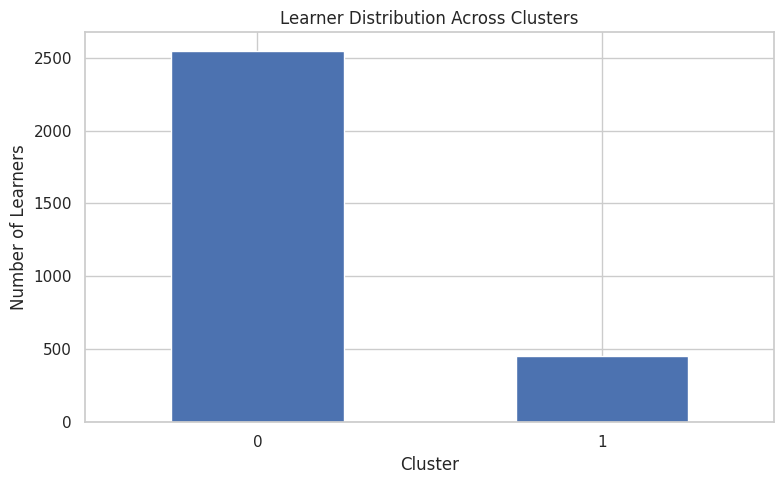

In [ ]:

import matplotlib.pyplot as plt

cluster_counts = learner_profiles["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
cluster_counts.plot(kind="bar")

plt.title("Learner Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Learners")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

print("FINAL MODEL EVALUATION")
print("======================")

if "best_k" in globals():
    print("Selected Clusters:", best_k)

if "final_silhouette" in globals():
    print("Silhouette Score:", round(final_silhouette, 4))

if "final_inertia" in globals():
    print("K-Means Inertia:", round(final_inertia, 2))

if "hit_rate_at_5" in globals() and "eligible_users" in globals():
    print("Eligible Learners:", eligible_users)
    if eligible_users > 0:
        print("Historical Course Recovery Rate@5:",
              round(hit_rate_at_5 * 100, 2), "%")


FINAL MODEL EVALUATION
Selected Clusters: 2
Silhouette Score: 0.4891
K-Means Inertia: 16069.3


In [ ]:

from google.colab import files

cluster_summary.to_csv(
    "EduPro_Cluster_Summary.csv",
    index=False
)

files.download("EduPro_Cluster_Summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>